In [1]:
import os

# --- 0. RESOURCE LIMITATION (Requested: 16 Threads) ---
# Limits the number of threads used by Numpy/Scipy/FakeSpectra to 16
# This prevents the code from hijacking the entire node.
num_cores = 20
os.environ["OMP_NUM_THREADS"] = "20"
os.environ["NUMEXPR_MAX_THREADS"] = "20"
os.environ["MKL_NUM_THREADS"] = "20"
os.environ["VECLIB_MAXIMUM_THREADS"] = "20"

import numpy as np
import h5py
import sys
import pickle
from tqdm import tqdm
import fake_spectra.spectra as spectra
import matplotlib.pyplot as plt

# --- 0. NEW CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

/tmp/ipykernel_434223/12275718.py:105: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc="lower right", ncol=3)


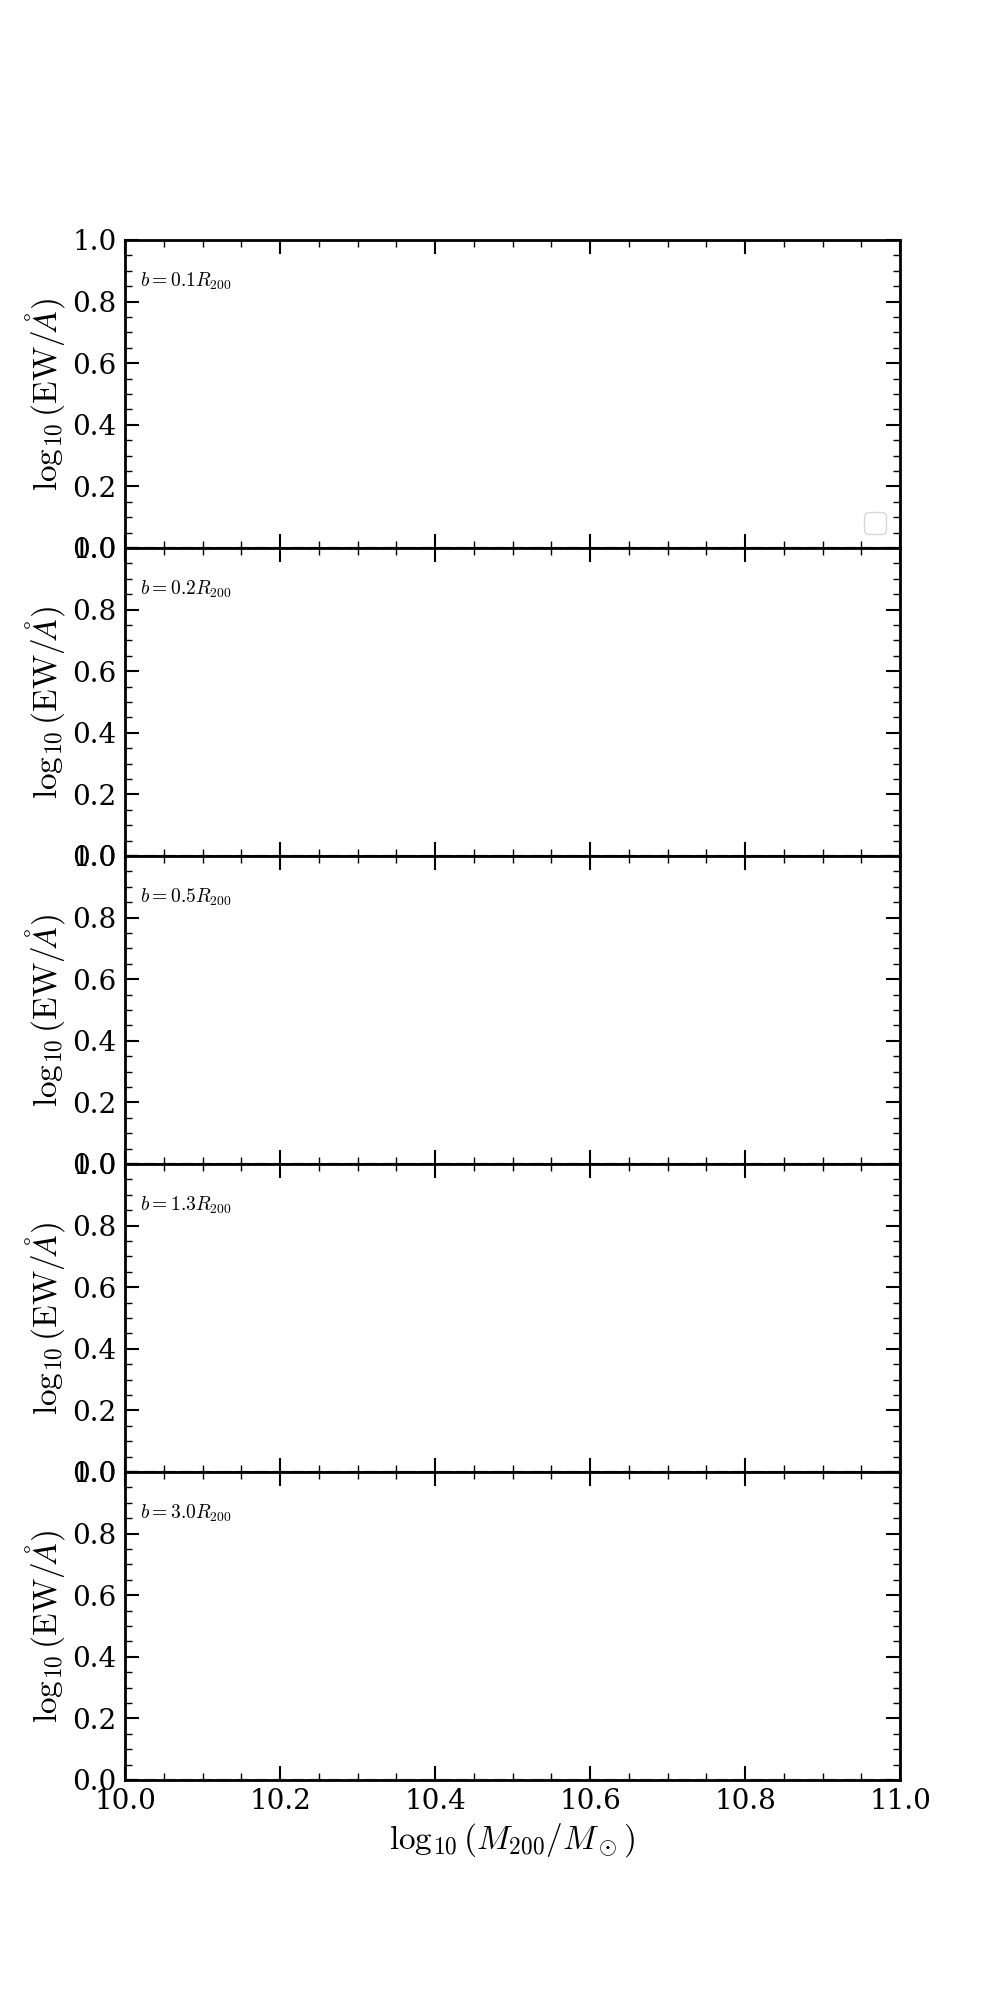

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURAÇÃO SIMPLES ---
INPUT_PKL = "TNG_Resolution_Comparison.pkl"

# Cores das simulações
sim_colors = {
    "TNG50-4": "C0", # Azul
    "TNG50-3": "C1", # Laranja
    "TNG50-2": "C2"  # Verde
}

# Carregar dados
with open(INPUT_PKL, 'rb') as f:
    master_data = pickle.load(f)

# Configurar Bins de Massa (Log10)
bins = np.linspace(10.0, 11.0, 9) 
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

# Criar Figura
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 20), sharex=True)
plt.subplots_adjust(hspace=0)

# Loop pelos 5 painéis
for i, ax in enumerate(axes):
    
    for sim_name, color in sim_colors.items():
        if sim_name not in master_data: continue
        
        halos = master_data[sim_name]
        
        # 1. Coletar dados
        all_mass = []
        all_ew = []
        
        for halo in halos:
            if i < len(halo['radii_data']):
                r_data = halo['radii_data'][i]
                if 'ew_individual' in r_data:
                    vals = r_data['ew_individual']
                    m_val = halo['mass']
                    all_mass.extend([m_val] * len(vals))
                    all_ew.extend(vals)
        
        all_mass = np.array(all_mass)
        all_ew = np.array(all_ew)
        
        # Filtro e Log
        mask = (all_ew > 0.01)
        log_mass = np.log10(all_mass[mask])
        log_ew = np.log10(all_ew[mask])
        
        # 2. Dados por bin
        violin_data = []
        valid_positions = []
        
        for b in range(len(bin_centers)):
            mask_bin = (log_mass >= bins[b]) & (log_mass < bins[b+1])
            data_in_bin = log_ew[mask_bin]
            
            if len(data_in_bin) > 5:
                violin_data.append(data_in_bin)
                valid_positions.append(bin_centers[b])
        
        # 3. Plotar Violino e Linhas Conectadas
        if len(violin_data) > 0:
            # Violino (Contorno apenas)
            parts = ax.violinplot(violin_data, positions=valid_positions, 
                                  widths=bin_width*0.8,
                                  showextrema=False, bw_method=0.2)
            
            for pc in parts['bodies']:
                pc.set_facecolor('none')
                pc.set_edgecolor(color)
                pc.set_linewidth(2)
                pc.set_alpha(0.7)
            
            # --- AQUI ESTÁ A MUDANÇA ---
            # Calcular medianas
            medians = [np.median(d) for d in violin_data]
            
            # Plotar bolinhas conectadas por linha ('-o')
            ax.plot(valid_positions, medians, '-o', color=color, 
                    linewidth=2, markersize=6, label=sim_name if i==0 else "")

    # Texto do parametro de impacto
    if len(halos) > 0:
        r_mult = halos[0]['radii_data'][i]['r_mult']
        ax.text(0.02, 0.85, f"$b = {r_mult:.1f} R_{{200}}$", transform=ax.transAxes)
    
    # Linha de referência em 0 (1 Angstrom)
    ax.axhline(0, color='k', linestyle='--', alpha=0.3)
    ax.set_ylim(0, 1)
    ax.set_ylabel(r"$\log_{10}(\mathrm{EW} / \AA)$")

# Eixo X
axes[-1].set_xlabel(r"$\log_{10}(M_{200} / M_\odot)$")
axes[-1].set_xlim(10.0, 11.0)

# Legenda (agora usa os labels definidos no ax.plot)
axes[0].legend(loc="lower right", ncol=3)

plt.show()